<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L04_classification_nn_tl/01ADS_L04_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lecture 04: Image classification and transfer learning with PyTorch

Second notebook of Lecture 04. The first notebook covered classification metrics, thresholds, calibration and
classical models on tabular data. Here we move to images: how an image becomes a tensor, what a convolutional
layer computes, how to train a small convolutional network from scratch, and how to reuse a network pretrained
on ImageNet (transfer learning) when we have little data and little time.

Running example: cats vs. dogs from CIFAR-10 (32×32 colour images). The task is small enough to train in minutes
and hard enough that a network trained from scratch clearly loses against a pretrained one.

## Schedule for today's lecture
- Images as tensors: shapes, scaling, normalisation and where the statistics come from
- What a convolution computes: kernels, stride, padding, pooling, receptive field
- A small CNN from scratch: data pipeline, augmentation, training loop, learning curves, a learning-rate failure
- Inside the network: filters, feature maps, flatten vs. global average pooling
- What a pretrained ResNet18 already knows; transfer learning: matching preprocessing, freezing, three fine-tuning regimes
- Pretrained networks as feature extractors: embeddings, logistic regression, PCA, nearest neighbours
- Looking inside ResNet18: feature maps at different depths, Grad-CAM, occlusion, your own photo
- Checklist and pointers

## 0. Setup

**GPU.** In Colab choose *Runtime → Change runtime type → T4 GPU*. With a GPU every training cell below runs live
(about 6 minutes in total on a T4). Without a GPU the notebook downloads checkpoints and training histories that
were produced with the same code and only evaluates them, so the whole notebook still runs in a few minutes.
You can force the second behaviour by setting `TRAIN = False`.

In [1]:
import copy
import json
import os
import random
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
plt.rcParams["figure.dpi"] = 100

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN = torch.cuda.is_available() and os.environ.get("FORCE_CPU_PATH") != "1"
print(f"torch {torch.__version__}, torchvision {torchvision.__version__}, device: {device}, TRAIN = {TRAIN}")

torch 2.9.0+cu128, torchvision 0.24.0+cpu, device: cuda, TRAIN = True


In [2]:
# All files of this lecture are read local-first and downloaded from GitHub when missing (Colab).
RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures/L04_classification_nn_tl"
CKPT_DIR = Path("checkpoints")
OUT_DIR = Path("outputs")
CKPT_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)


def fetch(relpath: str) -> Path:
    p = Path(relpath)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{relpath}", p)
    return p

## 1. Images as tensors

A colour image is an array of shape `height × width × 3` with integer intensities 0–255. PyTorch (and most
libraries built on it) stores batches of images as float tensors of shape **`(N, C, H, W)`**: batch, channels,
height, width. Two preprocessing steps happen before any network sees the data:

1. **Scaling** to the range $[0, 1]$ (`ToTensor()` divides by 255).
2. **Normalisation** per channel, $x' = (x - \mu_c) / \sigma_c$, so that the inputs have roughly zero mean and unit
   variance. Optimisation of deep networks is much easier with standardised inputs, exactly as with the
   `StandardScaler` in the previous notebook.

Where do $\mu_c$ and $\sigma_c$ come from? **From the training data only.** They are parameters of the
preprocessing, estimated on the training split and then applied unchanged to the validation and test splits.
Estimating them on all data (or on the test set) is the same leakage we discussed for tabular data in Lecture 03.
When we use a pretrained network, we must use **the statistics the network was trained with**, not our own.

In [3]:
DATA_ROOT = Path("data")
cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CLASS_NAMES = {0: "cat", 1: "dog"}


def cats_and_dogs(ds):
    # CIFAR-10 labels: 3 = cat, 5 = dog. We relabel dog = 1, cat = 0.
    targets = np.asarray(ds.targets)
    mask = np.isin(targets, [3, 5])
    return ds.data[mask], (targets[mask] == 5).astype(np.int64)


X_pool, y_pool = cats_and_dogs(cifar_train)   # 10 000 training images available
X_test, y_test = cats_and_dogs(cifar_test)    # 2 000 test images, never used for any decision

# stratified subset: 2 000 training + 500 validation images per class (keeps the training times short)
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in (0, 1):
    idx = rng.permutation(np.flatnonzero(y_pool == c))
    train_idx += idx[:2000].tolist()
    val_idx += idx[2000:2500].tolist()
X_train, y_train = X_pool[train_idx], y_pool[train_idx]
X_val, y_val = X_pool[val_idx], y_pool[val_idx]

print(f"train {X_train.shape}, val {X_val.shape}, test {X_test.shape}, dtype {X_train.dtype}")
print("class balance (train):", np.bincount(y_train))

train (4000, 32, 32, 3), val (1000, 32, 32, 3), test (2000, 32, 32, 3), dtype uint8
class balance (train): [2000 2000]


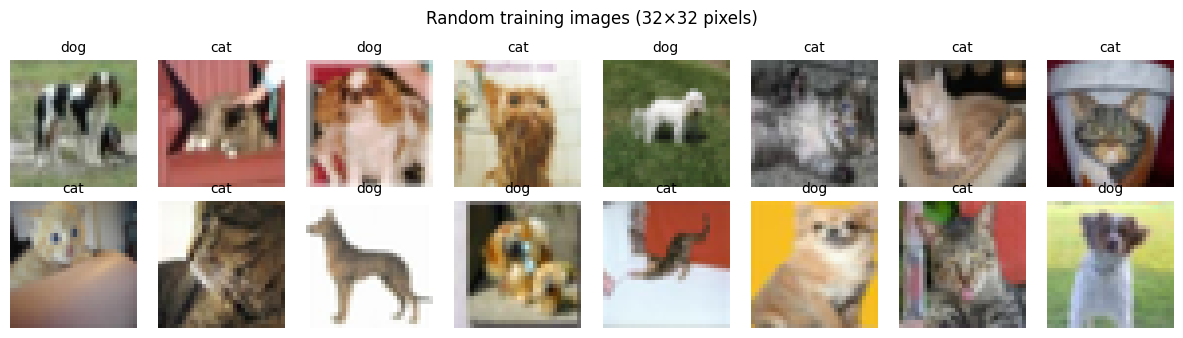

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.ravel(), rng.choice(len(X_train), 16, replace=False)):
    ax.imshow(X_train[i])
    ax.set_title(CLASS_NAMES[int(y_train[i])], fontsize=10)
    ax.axis("off")
fig.suptitle("Random training images (32×32 pixels)")
plt.tight_layout()

In [5]:
# numpy (N, H, W, C) uint8  ->  torch (N, C, H, W) float in [0, 1]
x = torch.from_numpy(X_train).permute(0, 3, 1, 2).float() / 255.0
print("tensor shape (N, C, H, W):", tuple(x.shape), "| range:", float(x.min()), "to", float(x.max()))

train_mean = x.mean(dim=(0, 2, 3))
train_std = x.std(dim=(0, 2, 3))
imagenet_mean = torch.tensor(ResNet18_Weights.IMAGENET1K_V1.transforms().mean)
imagenet_std = torch.tensor(ResNet18_Weights.IMAGENET1K_V1.transforms().std)

stats = pd.DataFrame(
    {"mean": train_mean.numpy(), "std": train_std.numpy(),
     "ImageNet mean": imagenet_mean.numpy(), "ImageNet std": imagenet_std.numpy()},
    index=["R", "G", "B"],
).round(3)
stats

tensor shape (N, C, H, W): (4000, 3, 32, 32) | range: 0.0 to 1.0


,mean,std,ImageNet mean,ImageNet std
R,0.497,0.254,0.485,0.229
G,0.460,0.249,0.456,0.224
B,0.415,0.254,0.406,0.225


The statistics of our 4 000 cat/dog images differ from the ImageNet constants (1.2 million photos of 1 000
classes). For the network trained from scratch we use **our training statistics**; for the pretrained ResNet18 we
will use **its ImageNet statistics**, because its first layer expects inputs on that scale. Both are computed
once and stored inside the transform, which is then applied to every split.

In [6]:
normalise = transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist())
sample = x[:1]
print("before normalisation: mean %.3f std %.3f" % (sample.mean(), sample.std()))
print("after  normalisation: mean %.3f std %.3f" % (normalise(sample).mean(), normalise(sample).std()))

before normalisation: mean 0.368 std 0.197
after  normalisation: mean -0.356 std 0.742


## 2. What a convolution computes

A dense (fully connected) layer connects every input pixel to every output unit. For a 32×32×3 image that is
3 072 inputs per unit and the layer has no idea that pixel (5, 5) is next to pixel (5, 6). A **convolutional layer**
slides a small kernel $K$ (typically 3×3) over the image and computes at every position

$$ (I * K)(i, j) = \sum_{u=0}^{k-1} \sum_{v=0}^{k-1} K(u, v)\, I(i + u, j + v) + b . $$

The same $k \times k$ weights are reused at every position (**weight sharing**), so the layer detects the same
pattern anywhere in the image and has very few parameters. Each kernel produces one output channel, a
**feature map**. Further vocabulary:

- **Padding** adds a border of zeros so that the output keeps the input size; **stride** $s$ moves the kernel by
  $s$ pixels and shrinks the output. Output size: $\lfloor (H + 2p - k)/s \rfloor + 1$.
- **Pooling** (max or average over 2×2 windows) halves the resolution and makes the representation a bit
  invariant to small shifts.
- The **receptive field** of a unit is the input region that influences it. It grows with every layer, so deep
  units "see" large parts of the image while early units see only a few pixels.

Let us apply a few hand-made kernels to a photo to see what a single convolution does.

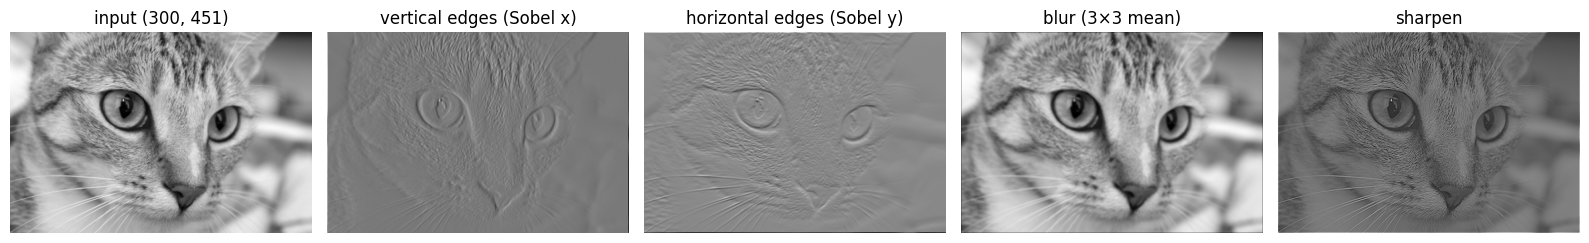

In [7]:
cat_img = Image.open(fetch("pics/chelsea.png")).convert("RGB")
gray = torch.tensor(np.asarray(cat_img.convert("L")), dtype=torch.float32)[None, None] / 255.0  # (1, 1, H, W)

kernels = {
    "vertical edges (Sobel x)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "horizontal edges (Sobel y)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "blur (3×3 mean)": [[1, 1, 1], [1, 1, 1], [1, 1, 1]],
    "sharpen": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(gray[0, 0], cmap="gray")
axes[0].set_title(f"input {tuple(gray.shape[2:])}")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    K = torch.tensor(k, dtype=torch.float32)
    K = K / K.sum() if K.sum() != 0 else K
    out = F.conv2d(gray, K[None, None], padding=1)
    ax.imshow(out[0, 0], cmap="gray")
    ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.tight_layout()

In [8]:
# stride, padding and pooling change the spatial size; channels are set by the number of kernels
conv_same = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)
conv_stride = nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1)
pool = nn.MaxPool2d(2)
with torch.no_grad():
    print("input             ", tuple(gray.shape))
    print("conv 3x3, pad 1   ", tuple(conv_same(gray).shape))
    print("conv 3x3, stride 2", tuple(conv_stride(gray).shape))
    print("max-pool 2x2      ", tuple(pool(conv_same(gray)).shape))

n_conv = sum(p.numel() for p in nn.Conv2d(3, 32, 3, padding=1).parameters())
n_dense = sum(p.numel() for p in nn.Linear(32 * 32 * 3, 32 * 32 * 32).parameters())
print(f"\nparameters of a 3->32 channel 3x3 convolution on a 32x32 image: {n_conv:,}")
print(f"parameters of a dense layer producing the same 32x32x32 output : {n_dense:,}")

input              (1, 1, 300, 451)
conv 3x3, pad 1    (1, 8, 300, 451)
conv 3x3, stride 2 (1, 8, 150, 226)
max-pool 2x2       (1, 8, 150, 225)



parameters of a 3->32 channel 3x3 convolution on a 32x32 image: 896
parameters of a dense layer producing the same 32x32x32 output : 100,696,064


A convolution that produces the same output volume as a dense layer needs about 100 000 times fewer parameters.
Learned kernels look like the hand-made ones in the first layer (edges, colour blobs) and become detectors of
textures, parts and whole objects deeper in the network, as we will see in Section 4 and Section 7.

## 3. A small CNN from scratch

### Data pipeline

A PyTorch `Dataset` returns one `(image, label)` pair, a `DataLoader` batches and shuffles them. The transforms are
where **augmentation** happens: for training we randomly crop (after 4 pixels of padding) and flip the image, which
creates a slightly different input every epoch and reduces overfitting. Validation and test images are only
scaled and normalised: we want to evaluate the model on the data as it is.

In [9]:
class ArrayDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = Image.fromarray(self.images[i])
        return self.transform(img), torch.tensor(self.labels[i], dtype=torch.float32)


cnn_train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    normalise,
])
cnn_eval_tf = transforms.Compose([transforms.ToTensor(), normalise])

BATCH = 64
cnn_train_loader = DataLoader(ArrayDataset(X_train, y_train, cnn_train_tf), batch_size=BATCH, shuffle=True)
cnn_val_loader = DataLoader(ArrayDataset(X_val, y_val, cnn_eval_tf), batch_size=256)
cnn_test_loader = DataLoader(ArrayDataset(X_test, y_test, cnn_eval_tf), batch_size=256)

xb, yb = next(iter(cnn_train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(cnn_train_loader))

one batch: (64, 3, 32, 32) (64,) | batches per epoch: 63


### What the network sees during training

Augmentation is applied on the fly: every epoch the network sees a slightly different version of each training
image, while validation and test images are evaluated as they are. Keep this in mind when reading learning curves:
the training metrics are measured on the harder, augmented views.

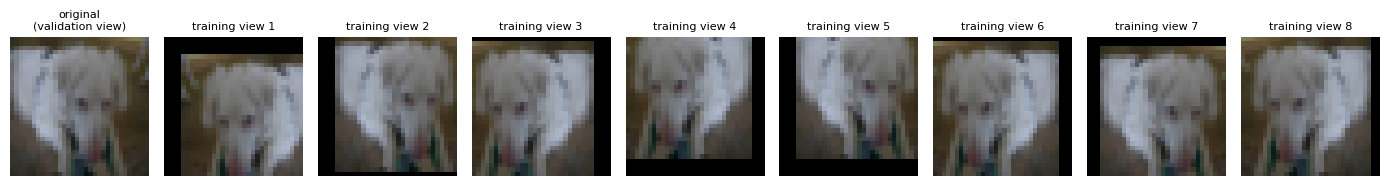

In [10]:
demo_idx = int(np.flatnonzero(y_train == 1)[0])
original = Image.fromarray(X_train[demo_idx])
augment = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()])
fig, axes = plt.subplots(1, 9, figsize=(14, 2.1))
axes[0].imshow(original)
axes[0].set_title("original\n(validation view)", fontsize=8)
for k, ax in enumerate(axes[1:], start=1):
    ax.imshow(augment(original))
    ax.set_title(f"training view {k}", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.tight_layout()

### Architecture

Two blocks of *convolution → batch normalisation → ReLU → max-pooling*, then a classifier on the flattened
feature maps. **Batch normalisation** standardises the activations inside the network (per channel, using batch
statistics during training and running averages at test time), which stabilises and speeds up training.
**Dropout** randomly switches off units during training as a regulariser. The network outputs one **logit**;
the sigmoid that turns it into $P(\text{dog})$ is folded into the loss (`BCEWithLogitsLoss`) for numerical
stability, exactly like the logistic regression in the first notebook.

In [11]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),   # 32 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 64 x 8 x 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                      # 64 * 8 * 8 = 4096
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, 1),                 # one logit: P(dog) = sigmoid(logit)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


simple_cnn = SimpleCNN().to(device)
print(simple_cnn)
print("parameters (total, trainable):", count_params(simple_cnn))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)
parameters (total, trainable): (544129, 544129)


### Training loop

PyTorch does not hide the training loop, which is the point: you see every step.

1. `model.train()` / `model.eval()` switch batch-norm and dropout between their training and inference behaviour.
2. For each batch: forward pass → loss → `loss.backward()` computes the gradients → `optimizer.step()` updates the
   weights → `optimizer.zero_grad()` clears the gradients for the next batch.
3. After each epoch evaluate on the validation set (`torch.no_grad()`, no gradients needed) and keep the weights of
   the **best epoch by validation loss**: this is early stopping with a checkpoint.

`set_mode()` contains one subtlety that we will need for transfer learning: a batch-norm layer whose parameters are
**frozen** must stay in `eval()` mode even while the rest of the network trains. Otherwise its running mean and
variance keep drifting towards our small data set and the frozen layers silently stop matching the pretrained
weights.

In [12]:
def set_mode(model, train: bool):
    model.train(train)
    if train:  # frozen batch-norm layers keep their pretrained running statistics
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                m.eval()


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    set_mode(model, training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb).squeeze(1)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0) == (yb > 0.5)).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def train_model(model, train_loader, val_loader, epochs, lr, weight_decay=1e-4):
    criterion = nn.BCEWithLogitsLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_loss, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        dt = time.time() - t0
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, dt)):
            history[k].append(float(v))
        if va_loss < best_loss:
            best_loss, best_state, best_epoch = va_loss, copy.deepcopy(model.state_dict()), epoch
        print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} | {dt:4.1f} s")
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    history["train_time"] = float(sum(history["epoch_time"]))
    history["device"] = str(device)
    return history


@torch.no_grad()
def predict_proba(model, loader):
    set_mode(model, False)
    probs = [torch.sigmoid(model(xb.to(device)).squeeze(1)).cpu() for xb, _ in loader]
    return torch.cat(probs).numpy()

### Checkpoints

Training on a GPU takes seconds to minutes; on two CPU cores it takes much longer. The helper below trains the model
when a GPU is available and otherwise downloads a checkpoint (the trainable weights and the batch-norm statistics
from `model.state_dict()`, stored in half precision) and the training history produced by the same code on a GPU. Either way the
test-set probabilities are computed once and stored with the history, so the evaluation cells are identical.

In [13]:
def save_checkpoint(model, history, name):
    # store only what training can change: trainable parameters and all buffers (batch-norm statistics), in half precision
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    all_params = {n for n, _ in model.named_parameters()}
    state = {k: (v.detach().cpu().half() if v.is_floating_point() else v.cpu())
             for k, v in model.state_dict().items() if k in trainable or k not in all_params}
    torch.save(state, CKPT_DIR / f"{name}.pt")
    with open(OUT_DIR / f"history_{name}.json", "w") as f:
        json.dump(history, f)


def load_checkpoint(model, name):
    # the frozen part is identical to the ImageNet weights that make_resnet18() already loaded
    state = torch.load(fetch(f"checkpoints/{name}.pt"), map_location="cpu", weights_only=True)
    result = model.load_state_dict({k: (v.float() if v.is_floating_point() else v) for k, v in state.items()}, strict=False)
    frozen = {n for n, p in model.named_parameters() if not p.requires_grad}
    assert not result.unexpected_keys and set(result.missing_keys) <= frozen, result
    model.to(device)
    with open(fetch(f"outputs/history_{name}.json")) as f:
        return json.load(f)


def fit_or_load(model, name, train_loader, val_loader, test_loader, epochs, lr):
    if TRAIN:
        history = train_model(model, train_loader, val_loader, epochs=epochs, lr=lr)
        history["test_probs"] = predict_proba(model, test_loader).tolist()
        save_checkpoint(model, history, name)
    else:
        history = load_checkpoint(model, name)
        print(f"loaded checkpoint '{name}': {len(history['train_loss'])} epochs, best epoch {history['best_epoch']}, "
              f"{history['train_time']:.0f} s of training on {history['device']}")
    history["name"] = name
    return history


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, key, label in zip(axes, ("loss", "acc"), ("binary cross-entropy", "accuracy")):
        ax.plot(epochs, history[f"train_{key}"], "o-", label="train")
        ax.plot(epochs, history[f"val_{key}"], "s-", label="validation")
        ax.axvline(history["best_epoch"], color="grey", ls="--", lw=1, label="best epoch")
        ax.set_xlabel("epoch")
        ax.set_ylabel(label)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()


def test_report(history, name=None):
    probs = np.asarray(history["test_probs"])
    pred = (probs >= 0.5).astype(int)
    acc, auc = accuracy_score(y_test, pred), roc_auc_score(y_test, probs)
    print(f"{name or history['name']}: test accuracy {acc:.3f}, ROC-AUC {auc:.3f}")
    return acc, auc

epoch  1 | train loss 0.711 acc 0.530 | val loss 0.668 acc 0.624 |  2.2 s


epoch  2 | train loss 0.674 acc 0.580 | val loss 0.653 acc 0.626 |  1.7 s


epoch  3 | train loss 0.660 acc 0.605 | val loss 0.633 acc 0.626 |  1.7 s


epoch  4 | train loss 0.650 acc 0.630 | val loss 0.608 acc 0.674 |  1.7 s


epoch  5 | train loss 0.631 acc 0.645 | val loss 0.590 acc 0.666 |  1.7 s


...

epoch 12 | train loss 0.561 acc 0.714 | val loss 0.521 acc 0.735 |  2.1 s


epoch 13 | train loss 0.562 acc 0.701 | val loss 0.503 acc 0.749 |  2.1 s


epoch 14 | train loss 0.553 acc 0.706 | val loss 0.502 acc 0.736 |  2.0 s


epoch 15 | train loss 0.548 acc 0.723 | val loss 0.560 acc 0.714 |  2.0 s


simple_cnn: test accuracy 0.724, ROC-AUC 0.820


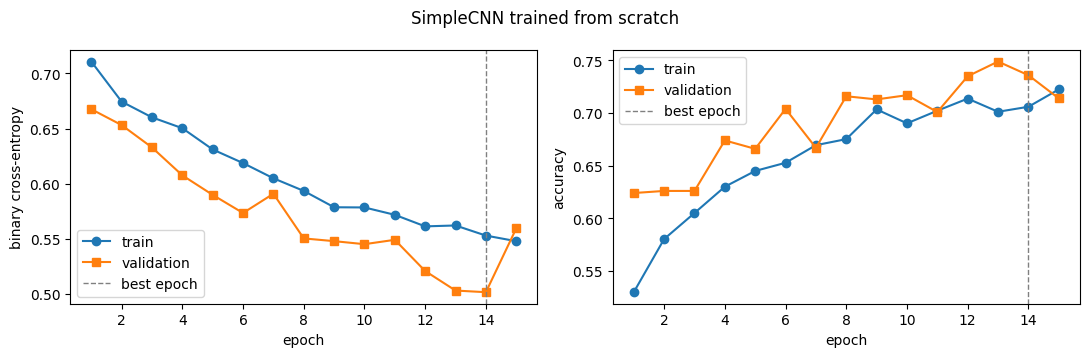

In [14]:
set_seed()
simple_cnn = SimpleCNN().to(device)
cnn_history = fit_or_load(simple_cnn, "simple_cnn", cnn_train_loader, cnn_val_loader, cnn_test_loader, epochs=15, lr=5e-4)
plot_history(cnn_history, "SimpleCNN trained from scratch")
cnn_acc, cnn_auc = test_report(cnn_history)

Both curves are still improving at the last epoch, and the validation curves lie *above* the training curves (higher
accuracy, lower loss). This is not a mistake: the training numbers are measured on randomly cropped and flipped
images with dropout active, so they are pessimistic, whereas validation images are evaluated unchanged with dropout
off. The network is therefore not yet memorising the 4 000 training images; it simply learns slowly and levels off
around 73–75 % validation accuracy, and the checkpoint of the best epoch is kept. With many more epochs the validation
loss would eventually turn upwards while the training loss keeps falling, the signature of overfitting that the
tabular MLP showed in the first notebook.

One practical lesson from preparing this notebook: with the common default `lr = 1e-3` this very network collapsed,
with this seed, to a constant prediction within the first batches (loss stuck at $\ln 2 = 0.693$, accuracy 0.5, for
all epochs). The dense layer on 4 096 flattened inputs makes the first Adam steps far too large, the ReLU units of the
classifier end up with negative inputs for every image and their gradient is zero from then on ("dead ReLUs"). A loss
frozen at $\ln 2$ is the signature of this failure. The fix is a smaller learning rate (5e-4 here), and structurally a
`BatchNorm1d` before the classifier's ReLU, a smaller flatten layer or global average pooling (Section 4). See for
yourself: the same network, three epochs with each learning rate. In our runs the `lr = 1e-3` curve sits on the
dashed $\ln 2$ line from the first epoch on.

epoch  1 | train loss 0.746 acc 0.497 | val loss 0.693 acc 0.500 |  2.0 s


epoch  2 | train loss 0.693 acc 0.500 | val loss 0.693 acc 0.500 |  1.8 s


epoch  3 | train loss 0.693 acc 0.500 | val loss 0.693 acc 0.500 |  1.7 s


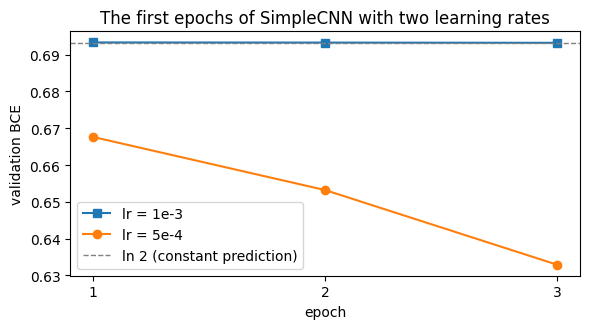

In [15]:
set_seed()
cnn_fast = SimpleCNN().to(device)
hist_fast = fit_or_load(cnn_fast, "simple_cnn_lr1e-3", cnn_train_loader, cnn_val_loader, cnn_test_loader, epochs=3, lr=1e-3)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot([1, 2, 3], hist_fast["val_loss"], "s-", label="lr = 1e-3")
ax.plot([1, 2, 3], cnn_history["val_loss"][:3], "o-", label="lr = 5e-4")
ax.axhline(np.log(2), color="grey", ls="--", lw=1, label="ln 2 (constant prediction)")
ax.set_xticks([1, 2, 3])
ax.set_xlabel("epoch")
ax.set_ylabel("validation BCE")
ax.set_title("The first epochs of SimpleCNN with two learning rates")
ax.legend()
plt.tight_layout()

Back to the network trained with `lr = 5e-4` and its errors.

              precision    recall  f1-score   support

         cat       0.76      0.66      0.70      1000
         dog       0.70      0.79      0.74      1000

    accuracy                           0.72      2000
   macro avg       0.73      0.72      0.72      2000
weighted avg       0.73      0.72      0.72      2000



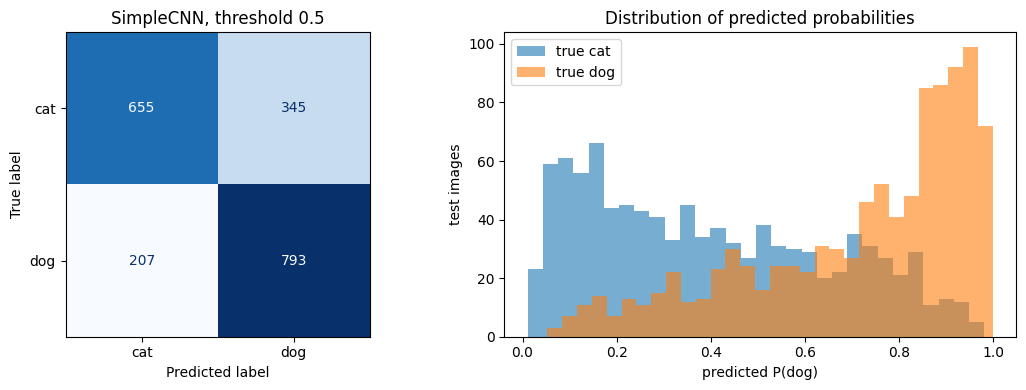

In [16]:
probs = np.asarray(cnn_history["test_probs"])
pred = (probs >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=list(CLASS_NAMES.values())))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=list(CLASS_NAMES.values())).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("SimpleCNN, threshold 0.5")
axes[1].hist(probs[y_test == 0], bins=30, alpha=0.6, label="true cat")
axes[1].hist(probs[y_test == 1], bins=30, alpha=0.6, label="true dog")
axes[1].set_xlabel("predicted P(dog)")
axes[1].set_ylabel("test images")
axes[1].legend()
axes[1].set_title("Distribution of predicted probabilities")
plt.tight_layout()

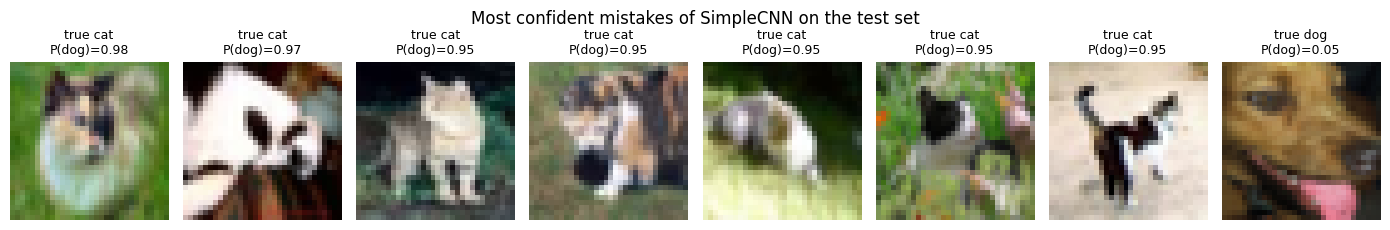

In [17]:
# the most confident mistakes: large |P(dog) - truth|
err = np.abs(probs - y_test)
worst = np.argsort(-err)[:8]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, i in zip(axes, worst):
    ax.imshow(X_test[i])
    ax.set_title(f"true {CLASS_NAMES[int(y_test[i])]}\nP(dog)={probs[i]:.2f}", fontsize=9)
    ax.axis("off")
fig.suptitle("Most confident mistakes of SimpleCNN on the test set")
plt.tight_layout()

## 4. Inside the network

### Learned filters

The first convolution has 32 kernels of shape 3×3×3. Shown as tiny RGB images they are hard to interpret at this
size, but a few of them are clearly edge and colour-contrast detectors like the hand-made Sobel kernels above.

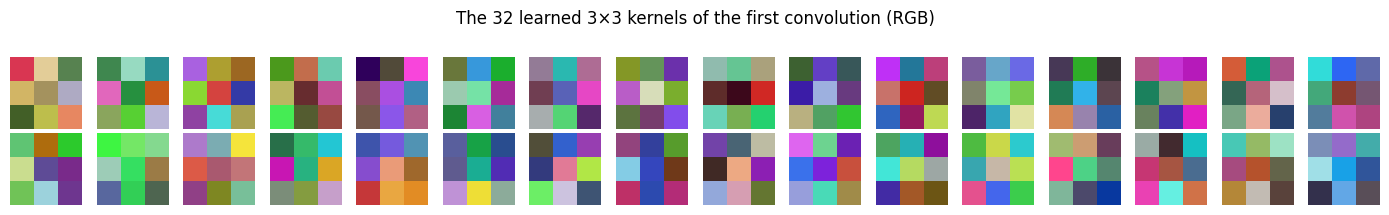

In [18]:
w = simple_cnn.features[0].weight.detach().cpu()           # (32, 3, 3, 3)
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(2, 16, figsize=(14, 2.2))
for ax, k in zip(axes.ravel(), w):
    ax.imshow(k.permute(1, 2, 0).numpy(), interpolation="nearest")
    ax.axis("off")
fig.suptitle("The 32 learned 3×3 kernels of the first convolution (RGB)")
plt.tight_layout()

### Feature maps

A feature map is the output of one kernel at every position. We run one test image through the first block
(conv → BN → ReLU) and through both blocks and show the first 16 channels of each (the maps below are taken before
each pooling, so they are 32×32 and 16×16). The resolution halves after each pooling (32 → 16 → 8) while the number
of channels grows (3 → 32 → 64): the network trades spatial detail for an increasing number of increasingly abstract
pattern detectors.

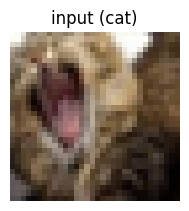

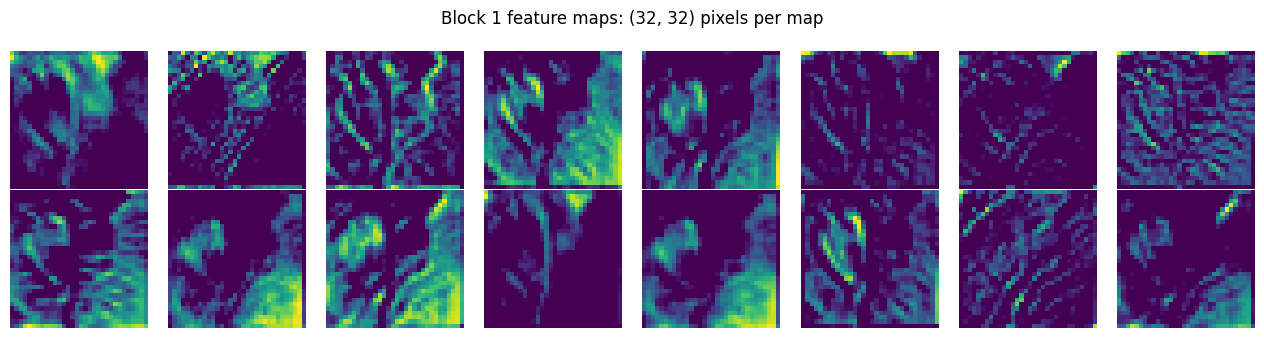

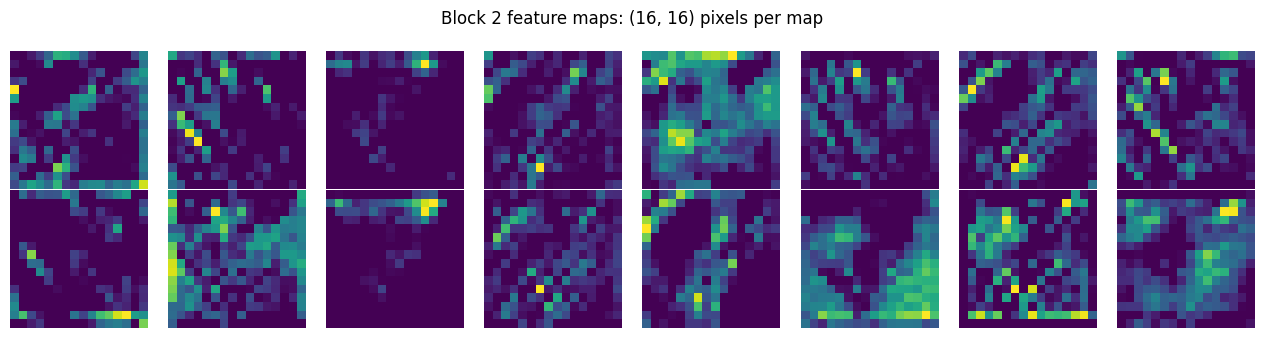

In [19]:
def show_maps(maps, title, n=16, ncols=8):
    maps = maps[:n].cpu()
    nrows = int(np.ceil(len(maps) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.6 * ncols, 1.7 * nrows))
    for ax, fm in zip(axes.ravel(), maps):
        ax.imshow(fm, cmap="viridis")
        ax.axis("off")
    for ax in axes.ravel()[len(maps):]:
        ax.axis("off")
    fig.suptitle(f"{title}: {tuple(maps.shape[-2:])} pixels per map")
    plt.tight_layout()


i = int(np.flatnonzero(y_test == 0)[3])
img = cnn_eval_tf(Image.fromarray(X_test[i])).unsqueeze(0).to(device)
simple_cnn.eval()
with torch.no_grad():
    block1 = simple_cnn.features[:3](img)[0]      # conv1 -> BN -> ReLU, before pooling: 32 x 32 x 32
    block2 = simple_cnn.features[:7](img)[0]      # after second ReLU: 64 x 16 x 16

plt.figure(figsize=(2.2, 2.2))
plt.imshow(X_test[i])
plt.axis("off")
plt.title(f"input ({CLASS_NAMES[int(y_test[i])]})")
show_maps(block1, "Block 1 feature maps")
show_maps(block2, "Block 2 feature maps")

### After the last feature map: flatten or pool?

The classifier needs a vector. `Flatten` turns the 64 × 8 × 8 feature maps into a vector of 4 096 numbers and
feeds it to a dense layer. That one layer holds 4 096 × 128 weights, more than 95 % of all parameters of the
network, and it is where this architecture would overfit with longer training. Modern networks (ResNet, EfficientNet, ...) instead apply
**global average pooling**: each channel is averaged over all positions, giving a vector of length equal to the
number of channels, independent of the image size, and the final dense layer is tiny.

In [20]:
flatten_head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 1))
gap_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 1))
feat = torch.zeros(1, 64, 8, 8)
print(f"flatten head : input {tuple(nn.Flatten()(feat).shape)} -> {count_params(flatten_head)[0]:,} parameters")
print(f"GAP head     : input {tuple(nn.Flatten()(nn.AdaptiveAvgPool2d(1)(feat)).shape)}   -> {count_params(gap_head)[0]:,} parameters")
print(f"share of SimpleCNN parameters in its first dense layer: "
      f"{simple_cnn.classifier[1].weight.numel() / count_params(simple_cnn)[0]:.1%}")

flatten head : input (1, 4096) -> 524,545 parameters
GAP head     : input (1, 64)   -> 65 parameters
share of SimpleCNN parameters in its first dense layer: 96.4%


## 5. Transfer learning with ResNet18

Training a good image classifier from scratch needs a lot of labelled images. **Transfer learning** starts from a
network that someone already trained on a large data set (here ResNet18 trained on ImageNet: 1.2 million photos,
1 000 classes, 11.7 million parameters) and adapts it to our task. The early layers detect edges, textures and
object parts that are useful for almost any photo, so we keep them and only learn what is specific to cats vs. dogs.

Three things have to be right:

1. **Preprocessing must match the pretrained weights.** `ResNet18_Weights.IMAGENET1K_V1.transforms()` tells us what
   the network expects: 224×224 inputs normalised with the ImageNet mean and standard deviation. Our 32×32 images
   are therefore resized to 224×224 and normalised with the ImageNet constants, not with our own statistics.
2. **The head must be replaced.** The last layer `fc` maps 512 features to the 1 000 ImageNet classes; we replace it
   by a new `Linear(512, 1)` for our single logit.
3. **Decide what is trainable.** Setting `requires_grad = False` on a parameter excludes it from the gradient
   computation ("freezing"); `train_model()` additionally hands only the trainable parameters to the optimiser
   (otherwise AdamW's weight decay would keep shrinking the frozen weights). Frozen batch-norm layers additionally
   stay in `eval()` mode (see `set_mode()` above).

We compare three regimes, from cheapest to most expensive:

| regime | trainable | learning rate | typical use |
|---|---|---|---|
| (a) feature extraction | new head `fc` only | 1e-3 | very little data, no GPU, fast |
| (b) partial fine-tuning | `layer4` + `fc` | 1e-4 | some data, moderate domain shift |
| (c) full fine-tuning | all layers | 1e-4 | more data or a very different domain |

Fine-tuning uses a **small learning rate**: the pretrained weights are already good and large steps would destroy
them in the first batches. A common refinement is a smaller learning rate for early layers than for the head.

In [21]:
weights = ResNet18_Weights.IMAGENET1K_V1
print(weights.transforms())

IMAGENET_MEAN, IMAGENET_STD = weights.transforms().mean, weights.transforms().std
tl_train_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
tl_eval_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
NUM_WORKERS = 0 if os.name == "nt" else 2   # resizing to 224 px is CPU work: use both Colab cores (worker processes need Linux here)
tl_train_loader = DataLoader(ArrayDataset(X_train, y_train, tl_train_tf), batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS)
tl_val_loader = DataLoader(ArrayDataset(X_val, y_val, tl_eval_tf), batch_size=128, num_workers=NUM_WORKERS)
tl_test_loader = DataLoader(ArrayDataset(X_test, y_test, tl_eval_tf), batch_size=128, num_workers=NUM_WORKERS)
xb, _ = next(iter(tl_train_loader))
print("one batch for ResNet18:", tuple(xb.shape))

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
one batch for ResNet18: (64, 3, 224, 224)


### What does the pretrained network already know?

Before we change anything, let us ask the ImageNet-trained ResNet18 what it sees in our images. Its last layer has
1 000 outputs, one per ImageNet class, and the classes include about 120 dog breeds and a handful of cat breeds. The
network has never seen our labels, yet its top guesses already separate cats from dogs: that is the knowledge we are
about to transfer. (The 32×32 CIFAR images are far from the photos it was trained on, so expect odd guesses there.)

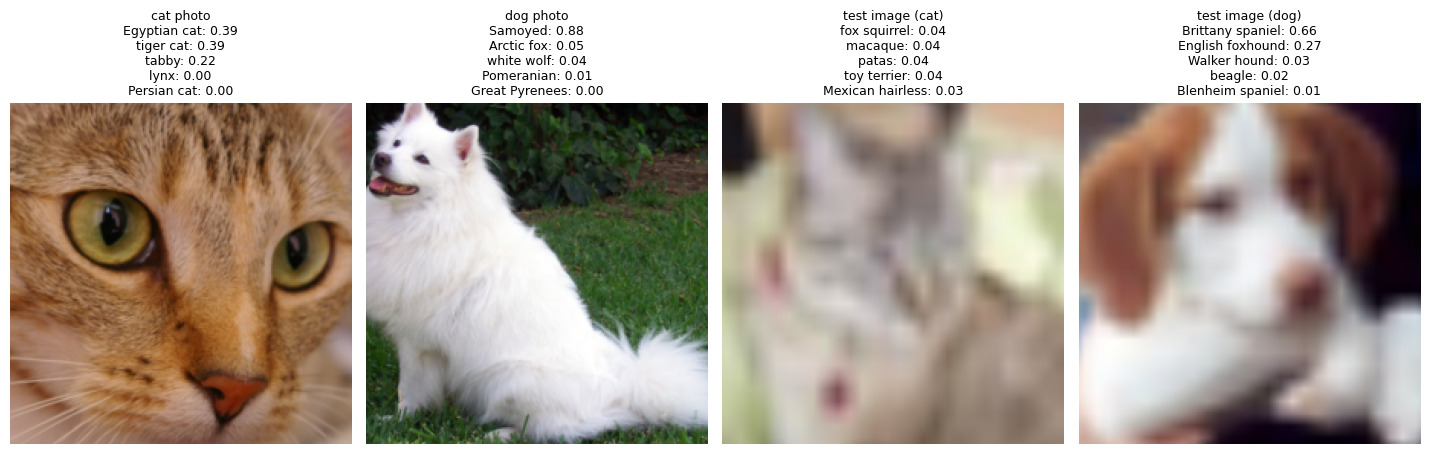

In [22]:
imagenet_net = resnet18(weights=weights).to(device).eval()
categories = weights.meta["categories"]
dog_img = Image.open(fetch("pics/dog.jpg")).convert("RGB")
samples = [("cat photo", cat_img), ("dog photo", dog_img)]
samples += [(f"test image ({CLASS_NAMES[c]})", Image.fromarray(X_test[int(np.flatnonzero(y_test == c)[1])])) for c in (0, 1)]

fig, axes = plt.subplots(1, len(samples), figsize=(3.6 * len(samples), 5.2))
with torch.no_grad():
    for ax, (title, im) in zip(axes, samples):
        probs = torch.softmax(imagenet_net(weights.transforms()(im).unsqueeze(0).to(device)), dim=1)[0]
        top = torch.topk(probs, 5)
        lines = [f"{categories[i]}: {p:.2f}" for p, i in zip(top.values.tolist(), top.indices.tolist())]
        ax.imshow(transforms.CenterCrop(224)(transforms.Resize(256)(im)))     # the 224x224 view the network gets
        ax.set_title(title + "\n" + "\n".join(lines), fontsize=9)
        ax.axis("off")
plt.tight_layout()

In [23]:
def make_resnet18(trainable: str):
    model = resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 1)        # new head for our single logit
    for name, p in model.named_parameters():
        if trainable == "fc":
            p.requires_grad = name.startswith("fc.")
        elif trainable == "layer4+fc":
            p.requires_grad = name.startswith("fc.") or name.startswith("layer4.")
        elif trainable == "all":
            p.requires_grad = True
        else:
            raise ValueError(trainable)
    return model.to(device)


for regime in ("fc", "layer4+fc", "all"):
    total, trainable = count_params(make_resnet18(regime))
    print(f"{regime:10s}: {trainable:>10,} trainable of {total:,} parameters ({trainable / total:.1%})")

fc        :        513 trainable of 11,177,025 parameters (0.0%)


layer4+fc :  8,394,241 trainable of 11,177,025 parameters (75.1%)


all       : 11,177,025 trainable of 11,177,025 parameters (100.0%)


epoch  1 | train loss 0.488 acc 0.783 | val loss 0.389 acc 0.841 |  7.1 s


epoch  2 | train loss 0.373 acc 0.851 | val loss 0.342 acc 0.855 |  6.7 s


epoch  3 | train loss 0.334 acc 0.863 | val loss 0.322 acc 0.866 |  6.5 s


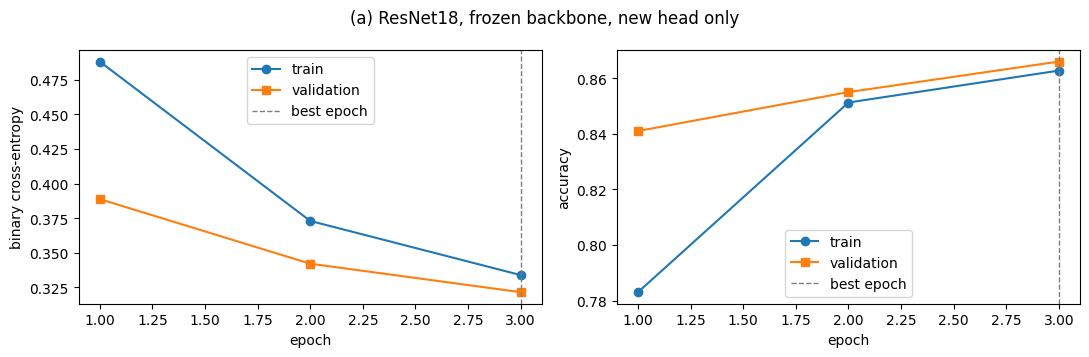

In [24]:
set_seed()
resnet_fc = make_resnet18("fc")
hist_fc = fit_or_load(resnet_fc, "resnet18_head", tl_train_loader, tl_val_loader, tl_test_loader, epochs=3, lr=1e-3)
plot_history(hist_fc, "(a) ResNet18, frozen backbone, new head only")

epoch  1 | train loss 0.310 acc 0.868 | val loss 0.232 acc 0.898 |  6.7 s


epoch  2 | train loss 0.139 acc 0.951 | val loss 0.206 acc 0.920 |  6.9 s


epoch  3 | train loss 0.073 acc 0.977 | val loss 0.221 acc 0.922 |  6.7 s


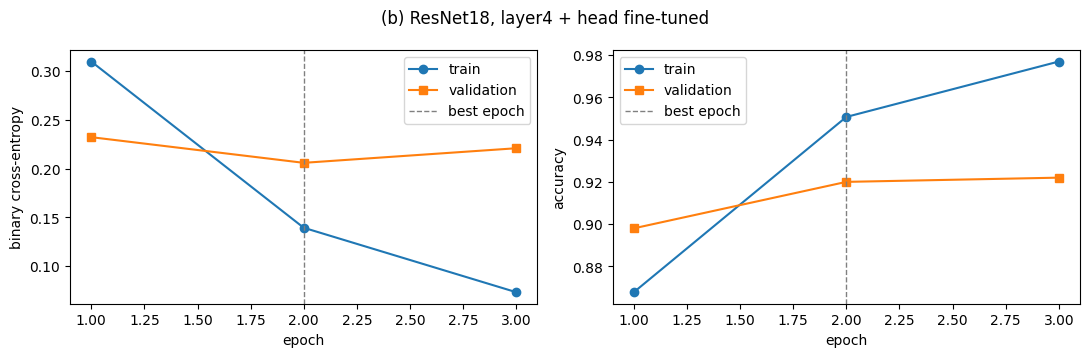

In [25]:
set_seed()
resnet_l4 = make_resnet18("layer4+fc")
hist_l4 = fit_or_load(resnet_l4, "resnet18_layer4_ft", tl_train_loader, tl_val_loader, tl_test_loader, epochs=3, lr=1e-4)
plot_history(hist_l4, "(b) ResNet18, layer4 + head fine-tuned")

epoch  1 | train loss 0.334 acc 0.855 | val loss 0.240 acc 0.898 |  8.2 s


epoch  2 | train loss 0.145 acc 0.945 | val loss 0.225 acc 0.906 |  9.7 s


epoch  3 | train loss 0.099 acc 0.967 | val loss 0.222 acc 0.925 |  8.8 s


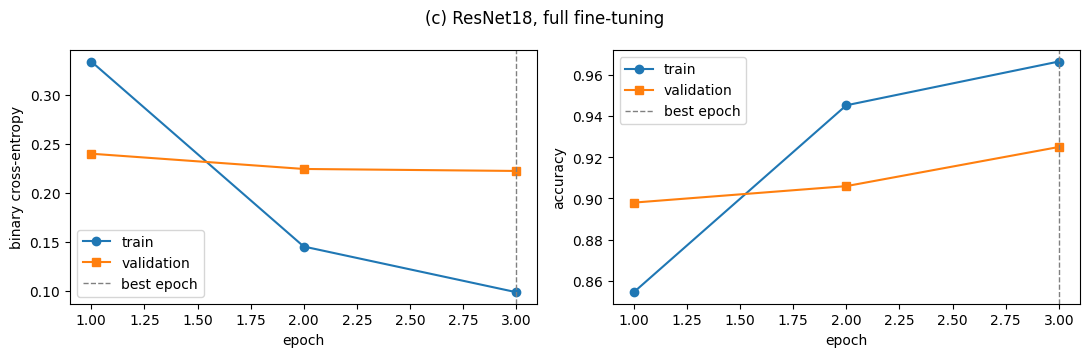

In [26]:
set_seed()
resnet_all = make_resnet18("all")
hist_all = fit_or_load(resnet_all, "resnet18_full_ft", tl_train_loader, tl_val_loader, tl_test_loader, epochs=3, lr=1e-4)
plot_history(hist_all, "(c) ResNet18, full fine-tuning")

In [27]:
rows = []
for label, model, hist in [
    ("SimpleCNN from scratch", simple_cnn, cnn_history),
    ("(a) ResNet18 frozen + head", resnet_fc, hist_fc),
    ("(b) ResNet18 layer4 + head", resnet_l4, hist_l4),
    ("(c) ResNet18 full fine-tuning", resnet_all, hist_all),
]:
    total, trainable = count_params(model)
    probs = np.asarray(hist["test_probs"])
    rows.append({
        "model": label,
        "trainable params": trainable,
        "epochs": len(hist["train_loss"]),
        "best epoch": hist["best_epoch"],
        f"train time [s] ({hist['device']})": round(hist["train_time"], 1),
        "val accuracy": round(hist["val_acc"][hist["best_epoch"] - 1], 3),
        "test accuracy": round(accuracy_score(y_test, probs >= 0.5), 3),
        "test ROC-AUC": round(roc_auc_score(y_test, probs), 3),
    })
results = pd.DataFrame(rows).set_index("model")
with open(OUT_DIR / "results.json", "w") as f:
    json.dump(results.reset_index().to_dict(orient="records"), f, indent=1)
results

,trainable params,epochs,best epoch,train time [s] (cuda),val accuracy,test accuracy,test ROC-AUC
model,,,,,,,
SimpleCNN from scratch,544129,15,14,28.7,0.736,0.724,0.820
(a) ResNet18 frozen + head,513,3,3,20.2,0.866,0.852,0.932
(b) ResNet18 layer4 + head,8394241,3,2,20.4,0.920,0.897,0.962
(c) ResNet18 full fine-tuning,11177025,3,3,26.7,0.925,0.904,0.964


Even the cheapest regime, which trains 513 parameters on top of frozen ImageNet features, beats the network trained
from scratch by a wide margin, and fine-tuning the last block or the whole network adds a few more points. Note the
cost column: a frozen backbone saves surprisingly little time here, because every epoch still pushes every image
through the whole backbone to recompute the same features. Computing those features once and training the head on
them in seconds is exactly what the next section does.

## 6. A pretrained network as a feature extractor

Remove the head (`fc = Identity`) and the pretrained ResNet18 becomes a function that maps any image to a vector of
512 numbers, an **embedding**. These vectors are a representation in which semantically similar images are close
to each other, so even a linear model on top of them works well. This is the same idea that text embeddings and
large language models use for documents, and it connects back to the first notebook: once we have a feature
vector, any tabular classifier applies.

In [28]:
@torch.no_grad()
def embed(model, loader):
    model.eval()
    return torch.cat([model(xb.to(device)).cpu() for xb, _ in loader]).numpy()


emb_file = OUT_DIR / "embeddings_resnet18.npz"
if TRAIN:
    extractor = resnet18(weights=weights).to(device)
    extractor.fc = nn.Identity()
    train_eval_loader = DataLoader(ArrayDataset(X_train, y_train, tl_eval_tf), batch_size=128)
    t0 = time.time()
    E_train, E_test = embed(extractor, train_eval_loader), embed(extractor, tl_test_loader)
    print(f"embedded {len(E_train) + len(E_test)} images in {time.time() - t0:.1f} s on {device}")
    np.savez_compressed(emb_file, train=E_train.astype(np.float16), test=E_test.astype(np.float16))
else:
    z = np.load(fetch(emb_file.as_posix()))
    E_train, E_test = z["train"].astype(np.float32), z["test"].astype(np.float32)
print("embedding matrices:", E_train.shape, E_test.shape)

embedded 6000 images in 7.6 s on cuda


embedding matrices: (4000, 512) (2000, 512)


logistic regression on frozen ResNet18 embeddings: test accuracy 0.863, ROC-AUC 0.934


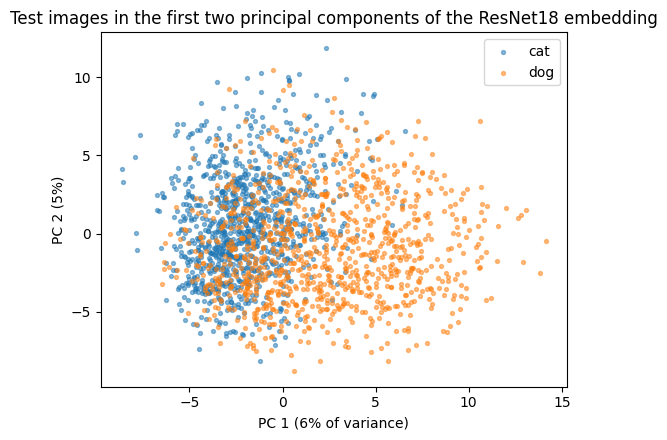

In [29]:
log_reg = LogisticRegression(max_iter=2000, C=0.5)
log_reg.fit(E_train, y_train)
emb_probs = log_reg.predict_proba(E_test)[:, 1]
print(f"logistic regression on frozen ResNet18 embeddings: test accuracy {accuracy_score(y_test, emb_probs >= 0.5):.3f}, "
      f"ROC-AUC {roc_auc_score(y_test, emb_probs):.3f}")

pca = PCA(n_components=2, random_state=SEED).fit(E_train)
P = pca.transform(E_test)
plt.figure(figsize=(5.5, 4.5))
for c, name in CLASS_NAMES.items():
    plt.scatter(*P[y_test == c].T, s=8, alpha=0.5, label=name)
plt.xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.title("Test images in the first two principal components of the ResNet18 embedding")
plt.legend()
plt.tight_layout()

### Nearest neighbours in the embedding space

If embeddings capture similarity, the training images closest to a test image (by cosine similarity of their
512-dimensional vectors) should look alike and mostly share its class. This is retrieval by embedding, the same
mechanism that image search and retrieval-augmented language models use, there with text embeddings.

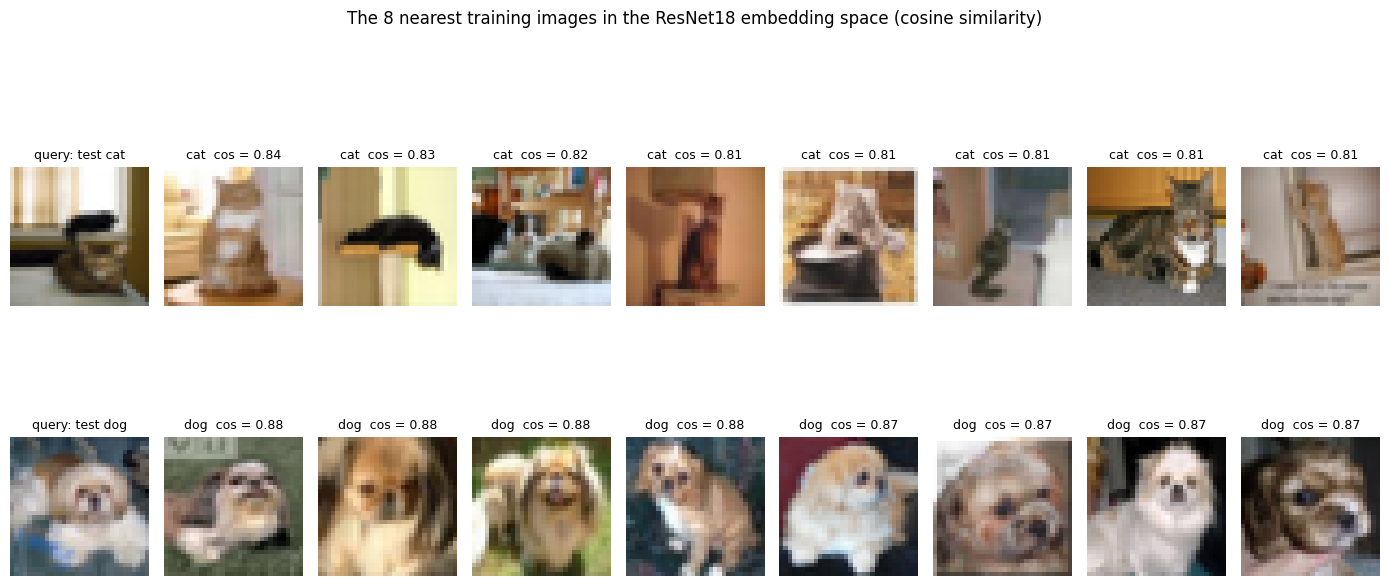

In [30]:
def unit(a):
    return a / np.linalg.norm(a, axis=1, keepdims=True)


E_train_unit, E_test_unit = unit(E_train), unit(E_test)
queries = [int(np.flatnonzero(y_test == 0)[5]), int(np.flatnonzero(y_test == 1)[5])]
fig, axes = plt.subplots(len(queries), 9, figsize=(14, 3.6 * len(queries)))
for row, q in zip(axes, queries):
    sims = E_train_unit @ E_test_unit[q]
    nearest = np.argsort(-sims)[:8]
    row[0].imshow(X_test[q])
    row[0].set_title(f"query: test {CLASS_NAMES[int(y_test[q])]}", fontsize=9)
    for ax, j in zip(row[1:], nearest):
        ax.imshow(X_train[j])
        ax.set_title(f"{CLASS_NAMES[int(y_train[j])]}  cos = {sims[j]:.2f}", fontsize=9)
    for ax in row:
        ax.axis("off")
fig.suptitle("The 8 nearest training images in the ResNet18 embedding space (cosine similarity)")
plt.tight_layout()

A plain logistic regression on 512 frozen features matches the accuracy of regime (a) at a fraction of the cost,
and the two classes already separate in a two-dimensional projection of the embedding. Whenever the data are small
and the domain is similar to the pretraining data, start here. Fine-tuning pays off when the domain is different
(medical images, satellite data, microscopy) or when the last percent matters.

## 7. Looking inside ResNet18

### Feature maps at different depths

A **forward hook** is a function that PyTorch calls with the output of a module every time it runs. We attach hooks
to the stem and the four stages of the fine-tuned ResNet18 and feed it a photo. The spatial resolution drops from
112×112 to 7×7 while the number of channels grows from 64 to 512; the early maps still look like filtered versions
of the photo, the late ones respond to abstract parts and are hard to read by eye.

fine-tuned ResNet18 on the photo: P(dog) = 0.000


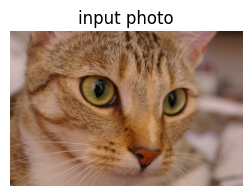

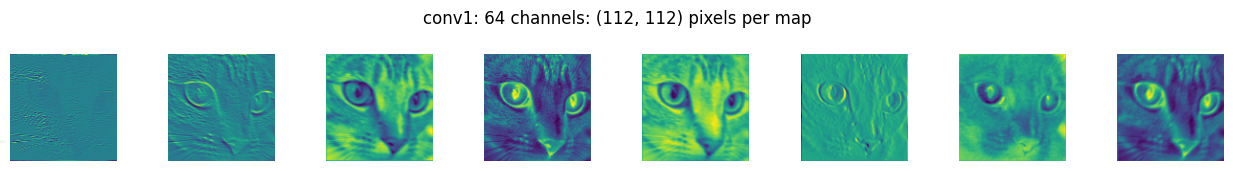

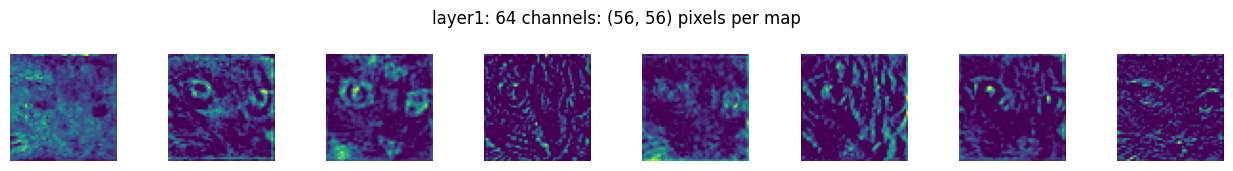

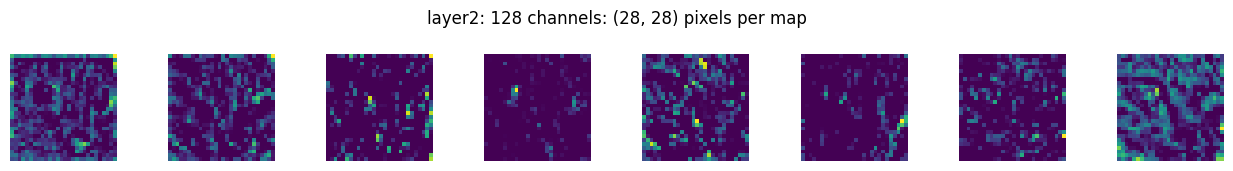

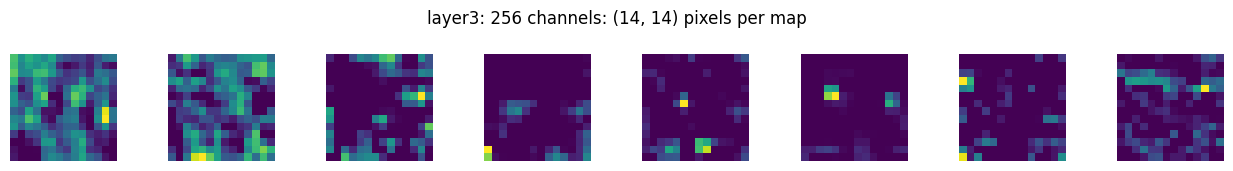

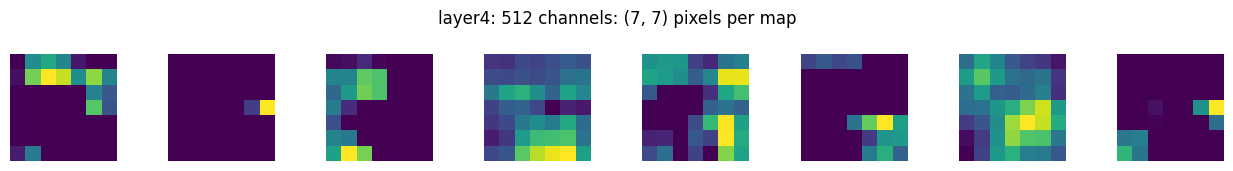

In [31]:
activations = {}


def save_activation(name):
    def hook(module, inputs, output):
        activations[name] = output.detach()
    return hook


handles = [getattr(resnet_all, n).register_forward_hook(save_activation(n)) for n in ("conv1", "layer1", "layer2", "layer3", "layer4")]
photo = weights.transforms()(cat_img).unsqueeze(0).to(device)
resnet_all.eval()
with torch.no_grad():
    p_dog = torch.sigmoid(resnet_all(photo)).item()
for h in handles:
    h.remove()
print(f"fine-tuned ResNet18 on the photo: P(dog) = {p_dog:.3f}")

plt.figure(figsize=(3, 3))
plt.imshow(cat_img)
plt.axis("off")
plt.title("input photo")
for n in ("conv1", "layer1", "layer2", "layer3", "layer4"):
    act = activations[n][0]
    show_maps(act, f"{n}: {act.shape[0]} channels", n=8, ncols=8)

### Grad-CAM: where does the network look?

Grad-CAM (Selvaraju et al., 2017) explains a prediction with the last convolutional feature maps. The gradient of
the class score with respect to each channel of `layer4` tells how much that channel matters for the decision; the
feature maps weighted by these importances and passed through a ReLU give a 7×7 heat map of the evidence, which we
upsample onto the photo.

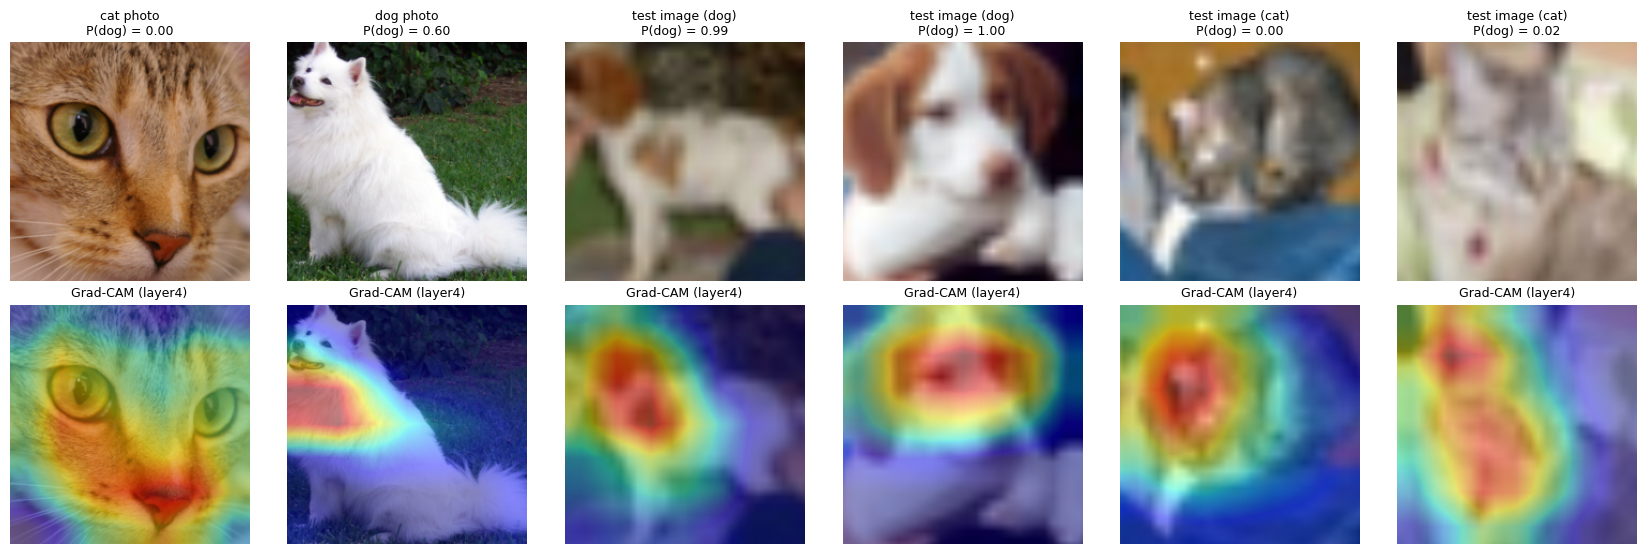

In [32]:
def grad_cam(model, x, target_layer):
    store = {}

    def forward_hook(module, inputs, output):
        output.retain_grad()
        store["act"] = output

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()
    model.zero_grad()
    x = x.requires_grad_(True)            # so that the activations carry gradients even with a frozen backbone
    logit = model(x).squeeze()
    p = torch.sigmoid(logit).item()
    score = logit if p >= 0.5 else -logit      # evidence for the predicted class
    score.backward()
    handle.remove()
    act, grad = store["act"][0], store["act"].grad[0]           # (C, h, w)
    weights_c = grad.mean(dim=(1, 2))                           # importance of each channel
    cam = F.relu((weights_c[:, None, None] * act).sum(0))
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), p


photos = [("cat photo", cat_img), ("dog photo", dog_img)]
for i in np.flatnonzero(y_test == 1)[:2].tolist() + np.flatnonzero(y_test == 0)[:2].tolist():
    photos.append((f"test image ({CLASS_NAMES[int(y_test[i])]})", Image.fromarray(X_test[i])))

fig, axes = plt.subplots(2, len(photos), figsize=(2.8 * len(photos), 5.6))
for j, (title, im) in enumerate(photos):
    x = weights.transforms()(im).unsqueeze(0).to(device)
    cam, p = grad_cam(resnet_all, x, resnet_all.layer4)
    shown = transforms.CenterCrop(224)(transforms.Resize(256)(im))   # exactly what weights.transforms() feeds the network
    axes[0, j].imshow(shown)
    axes[0, j].set_title(f"{title}\nP(dog) = {p:.2f}", fontsize=9)
    axes[1, j].imshow(shown)
    axes[1, j].imshow(np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((224, 224), Image.BILINEAR)), cmap="jet", alpha=0.45)
    axes[1, j].set_title("Grad-CAM (layer4)", fontsize=9)
    for ax in axes[:, j]:
        ax.axis("off")
plt.tight_layout()

The heat maps concentrate on the animal's head and body rather than on the background, a quick sanity check that
the network uses the right evidence. When Grad-CAM highlights backgrounds, watermarks or image borders, the model has
found a shortcut in the training data and will not generalise.

Compare the probabilities as well. The network was fine-tuned on blurry 32×32 images, so a sharp high-resolution
photo is a **domain shift**: whatever the two photos score in this run, do not expect those scores to be as reliable
as the scores of the test images, which look like the training data. Two photos prove nothing either way: a model is
reliable only on data that resembles what it was trained on, and a single confident output is not evidence of
reliability.

### Occlusion: cover a part of the image and watch the prediction

Grad-CAM needs gradients and a convolutional layer. A model-agnostic alternative is **occlusion sensitivity**: slide a
grey patch over the image, record how much the evidence for the predicted class drops, and draw the drops as a heat
map. It costs one forward pass per patch position (here an 8×8 grid), so it is slower, but it works for any
classifier and needs no access to its insides.

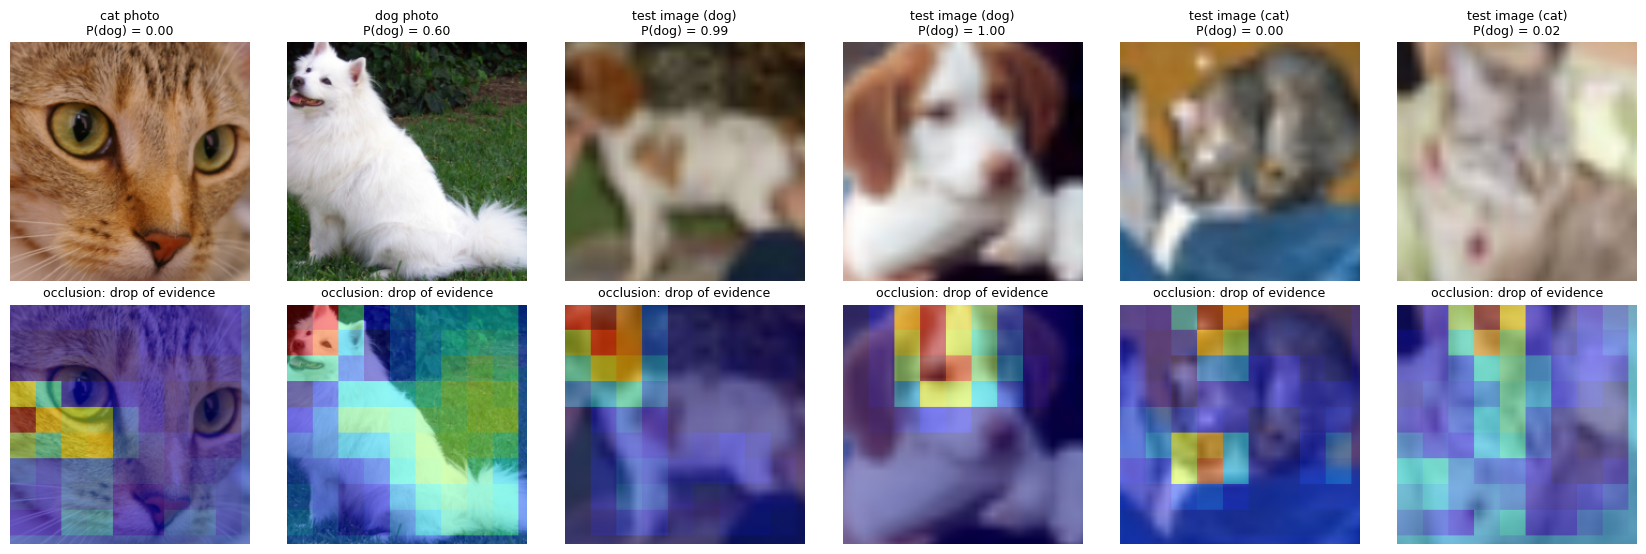

In [33]:
@torch.no_grad()
def occlusion_map(model, im, patch=48, stride=24):
    x = weights.transforms()(im).unsqueeze(0).to(device)
    model.eval()
    base = torch.sigmoid(model(x)).item()
    sign = 1.0 if base >= 0.5 else -1.0                      # evidence for the predicted class
    positions = [(y0, x0) for y0 in range(0, 224 - patch + 1, stride) for x0 in range(0, 224 - patch + 1, stride)]
    occluded = x.repeat(len(positions), 1, 1, 1)
    for k, (y0, x0) in enumerate(positions):
        occluded[k, :, y0:y0 + patch, x0:x0 + patch] = 0      # 0 after normalisation = the mean colour
    probs = torch.cat([torch.sigmoid(model(occluded[i:i + 32])).squeeze(1) for i in range(0, len(positions), 32)]).cpu().numpy()
    heat, count = np.zeros((224, 224)), np.zeros((224, 224))
    for (y0, x0), p in zip(positions, probs):
        heat[y0:y0 + patch, x0:x0 + patch] += sign * (base - p)
        count[y0:y0 + patch, x0:x0 + patch] += 1
    return heat / np.maximum(count, 1), base


fig, axes = plt.subplots(2, len(photos), figsize=(2.8 * len(photos), 5.6))
for j, (title, im) in enumerate(photos):
    heat, p = occlusion_map(resnet_all, im)
    shown = transforms.CenterCrop(224)(transforms.Resize(256)(im))
    axes[0, j].imshow(shown)
    axes[0, j].set_title(f"{title}\nP(dog) = {p:.2f}", fontsize=9)
    axes[1, j].imshow(shown)
    axes[1, j].imshow(heat, cmap="jet", alpha=0.45)
    axes[1, j].set_title("occlusion: drop of evidence", fontsize=9)
    for ax in axes[:, j]:
        ax.axis("off")
plt.tight_layout()

### Try your own photo

`explain_image()` takes a URL, a local file or a PIL image, classifies it with the fine-tuned network and shows the
Grad-CAM. Try your own cat or dog, a drawing, a plush toy, a photo rotated by 90 degrees, or a fox: the network has
only two classes and will force everything into one of them, with a confidence that says nothing about whether the
image is a cat or a dog at all. In Colab you can also upload a file with the commented lines.

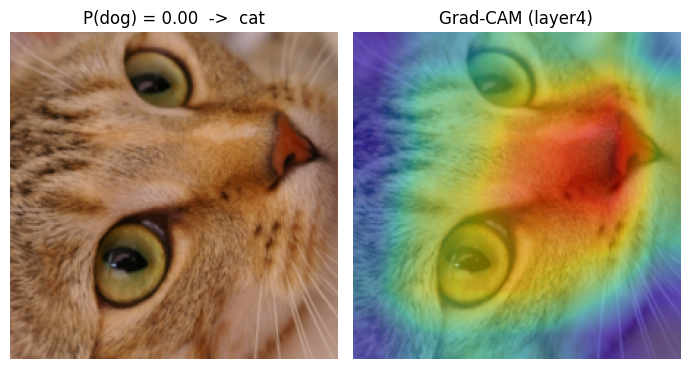

In [34]:
def explain_image(source, model=None):
    model = resnet_all if model is None else model
    if isinstance(source, Image.Image):
        im = source.convert("RGB")
    elif str(source).startswith("http"):
        im = Image.open(urllib.request.urlopen(str(source))).convert("RGB")
    else:
        im = Image.open(source).convert("RGB")
    x = weights.transforms()(im).unsqueeze(0).to(device)
    cam, p = grad_cam(model, x, model.layer4)
    shown = transforms.CenterCrop(224)(transforms.Resize(256)(im))
    heat = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((224, 224), Image.BILINEAR))
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.8))
    axes[0].imshow(shown)
    axes[0].set_title(f"P(dog) = {p:.2f}  ->  {CLASS_NAMES[int(p >= 0.5)]}")
    axes[1].imshow(shown)
    axes[1].imshow(heat, cmap="jet", alpha=0.45)
    axes[1].set_title("Grad-CAM (layer4)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()


explain_image(cat_img.rotate(90, expand=True))      # the same cat rotated by 90 degrees: still a cat?
# explain_image("https://example.org/your_photo.jpg")                                       # any image URL
# from google.colab import files; name = next(iter(files.upload())); explain_image(name)   # upload in Colab

## 8. Checklist and what comes next

**Before training**
- Split first, then compute every statistic (normalisation, class weights) on the training split only.
- With a pretrained network use *its* preprocessing (`weights.transforms()`), not your own statistics.
- Augment the training data only; validation and test images are evaluated as they are.

**Choosing a regime**
- Little data, similar domain, no GPU: frozen embeddings + logistic regression (Section 6) or a new head (regime a).
- Some data or moderate domain shift: unfreeze the last block(s), learning rate about 1e-4 (regime b).
- Much data or a very different domain: full fine-tuning with a small learning rate, longer training (regime c).
- Frozen batch-norm layers stay in `eval()`; check the number of trainable parameters before training.

**While training**
- Keep the best checkpoint by validation loss; watch the gap between training and validation curves.
- Report accuracy *and* a threshold-free metric (ROC-AUC); tune the threshold on validation data only.
- Look at the most confident mistakes and at Grad-CAM before trusting the number.

**What comes next**
- Model zoos: `torchvision.models`, [timm](https://github.com/huggingface/pytorch-image-models) (hundreds of
  pretrained CNNs and vision transformers), [Hugging Face](https://huggingface.co/models?pipeline_tag=image-classification).
- Vision transformers (ViT) and CLIP, which embeds images and text in the same space, so a classifier can be built
  from class *names* without any training images (zero-shot classification).
- Object detection and segmentation reuse the same pretrained backbones.

**References**
- He et al. (2016), *Deep Residual Learning for Image Recognition* (ResNet).
- Selvaraju et al. (2017), *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*.
- PyTorch tutorials: [Transfer Learning for Computer Vision](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html),
  [Training a Classifier](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html).